# Non-Invasive Neonatal Jaundice Screening using 1D-CNN
## Based on: Makhloughi et al. (2025) — Scientific Reports
**DOI**: 10.1038/s41598-025-96100-9

### Pipeline Overview
1. **Load** NeoJaundice dataset (2235 images, 745 patients, 3 body regions each)
2. **Preprocess** — LAB white balance → HSV skin segmentation → RGB+HSV feature extraction
3. **Feature Engineering** — Per-channel statistics (mean, std, min, max, median, skew) → compact 1D vector
4. **Patient-level split** — 70/10/20 train/val/test (no data leakage)
5. **1D-CNN Regression** — Predict TSB (mg/dL)
6. **1D-CNN Classification** — 3-class jaundice severity (0–5, 5–10, >10 mg/dL)
7. **Evaluation & Visualization** — RMSE, MAE, R², Accuracy, Precision, Recall, F1

---

In [1]:
# ════════════════════════════════════════════════════════════════
# Cell 1: Imports & Configuration
# ════════════════════════════════════════════════════════════════
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy import stats as sp_stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report
)
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
import time, json, warnings
warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ── Paths ──
IMAGE_DIR = '/Users/shubhbhateja/College/minor_project/images'
CSV_PATH  = '/Users/shubhbhateja/College/minor_project/NeoJaundice/chd_jaundice_published_2.csv'
SAVE_DIR  = '/Users/shubhbhateja/College/minor_project/development'

print(f'TensorFlow : {tf.__version__}')
print(f'GPU        : {tf.config.list_physical_devices("GPU")}')
print(f'NumPy      : {np.__version__}')

TensorFlow : 2.20.0
GPU        : []
NumPy      : 2.4.2


---
## 1 · Load & Explore the NeoJaundice Dataset

Dataset shape      : (2235, 8)
Columns            : ['patient_id', 'image_idx', 'gender', 'gestational_age', 'age(day)', 'weight', 'blood(mg/dL)', 'Treatment']
Unique patients    : 745
Images per patient : [3]

TSB statistics:
count    2235.000000
mean       11.206846
std         5.213196
min         0.000000
25%         7.400000
50%        11.800000
75%        15.100000
max        25.700000
Name: blood(mg/dL), dtype: float64

Class distribution:
  Class 0 (0-5 mg/dL): 354 (15.8%)
  Class 1 (5-10 mg/dL): 522 (23.4%)
  Class 2 (>10 mg/dL): 1359 (60.8%)


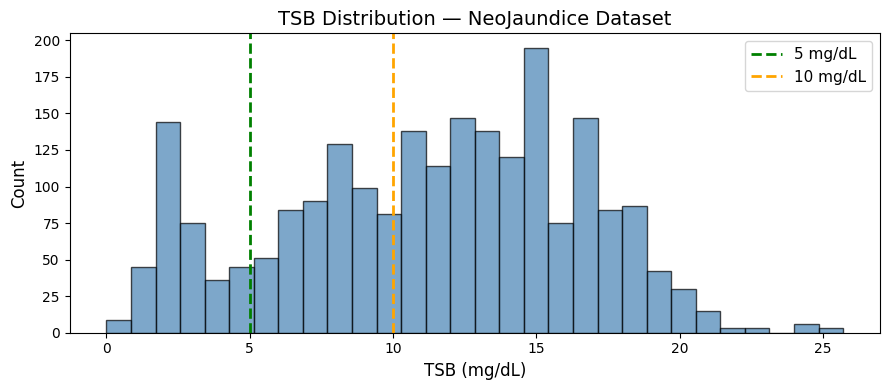

In [2]:
# ════════════════════════════════════════════════════════════════
# Cell 2: Load CSV and explore
# ════════════════════════════════════════════════════════════════
df = pd.read_csv(CSV_PATH)
print(f'Dataset shape      : {df.shape}')
print(f'Columns            : {list(df.columns)}')
print(f'Unique patients    : {df["patient_id"].nunique()}')
print(f'Images per patient : {df.groupby("patient_id").size().unique()}')
print(f'\nTSB statistics:')
print(df['blood(mg/dL)'].describe())

# 3-class labels per paper: 0-5 → 0, 5-10 → 1, >10 → 2
def tsb_to_class(val):
    if val <= 5:  return 0
    elif val <= 10: return 1
    else: return 2

df['bilirubin_class'] = df['blood(mg/dL)'].apply(tsb_to_class)
class_names = ['0-5 mg/dL', '5-10 mg/dL', '>10 mg/dL']
print(f'\nClass distribution:')
for c in range(3):
    n = (df['bilirubin_class'] == c).sum()
    print(f'  Class {c} ({class_names[c]}): {n} ({n/len(df)*100:.1f}%)')

# TSB histogram
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df['blood(mg/dL)'], bins=30, edgecolor='black', alpha=0.7, color='steelblue')
ax.axvline(5, color='green', ls='--', lw=2, label='5 mg/dL')
ax.axvline(10, color='orange', ls='--', lw=2, label='10 mg/dL')
ax.set_xlabel('TSB (mg/dL)', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('TSB Distribution — NeoJaundice Dataset', fontsize=14)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

---
## 2 · Preprocessing Pipeline

Per the paper:
1. **LAB white balance** — colour calibration using the yellow card reference
2. **HSV skin segmentation** — isolate neonatal skin ROI
3. **RGB + HSV extraction** — 6 colour channels from skin pixels
4. **Statistical feature vector** — per-channel stats (mean, std, min, max, median, skewness) → **(6 channels × 6 stats = 36-dim)** feature vector per image
5. Feed the feature vectors into a **1D-CNN** treating the 36-dim vector as a short 1D sequence

In [3]:
# ════════════════════════════════════════════════════════════════
# Cell 3: Preprocessing functions
# ════════════════════════════════════════════════════════════════
IMG_SIZE = 128  # paper uses reasonable resize


def lab_white_balance(img):
    """LAB-based white balance.
    Shifts a,b channels proportionally to luminance toward neutral (128)."""
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    avg_a, avg_b = np.mean(a), np.mean(b)
    l_f = l.astype(np.float32) / 255.0
    a = np.clip(a.astype(np.float32) - (avg_a - 128) * l_f, 0, 255).astype(np.uint8)
    b = np.clip(b.astype(np.float32) - (avg_b - 128) * l_f, 0, 255).astype(np.uint8)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2RGB)


def skin_mask_hsv(img):
    """HSV-based skin segmentation — returns binary mask."""
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    lower = np.array([0, 20, 70])
    upper = np.array([20, 255, 255])
    mask = cv2.inRange(hsv, lower, upper)
    # Morphological clean-up
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    return mask


def extract_features(img_path, img_size=IMG_SIZE):
    """Full pipeline for one image → 36-dim feature vector.
    
    Steps:
      1. Load & resize
      2. LAB white balance
      3. HSV skin segmentation
      4. Extract RGB+HSV skin pixels
      5. Compute per-channel statistics
    
    Returns: np.array of shape (36,) — [R_stats, G_stats, B_stats, H_stats, S_stats, V_stats]
             where stats = [mean, std, min, max, median, skewness]
    """
    img = cv2.imread(img_path)
    if img is None:
        return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (img_size, img_size))
    img = lab_white_balance(img)
    
    mask = skin_mask_hsv(img)
    skin_coords = np.where(mask > 0)
    
    # Fallback: if very few skin pixels, use central region
    if len(skin_coords[0]) < 50:
        h, w = img.shape[:2]
        ch, cw = h // 4, w // 4
        skin_coords = (np.arange(ch, 3*ch).repeat(2*cw),
                        np.tile(np.arange(cw, 3*cw), 2*ch))
    
    # RGB pixels
    rgb = img[skin_coords[0], skin_coords[1], :].astype(np.float32)  # (N, 3)
    # HSV pixels
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    hsv_pix = hsv[skin_coords[0], skin_coords[1], :].astype(np.float32)  # (N, 3)
    
    # Combine → (N, 6)
    combined = np.concatenate([rgb, hsv_pix], axis=1)  # R, G, B, H, S, V
    
    # Per-channel statistics → 6 stats × 6 channels = 36
    feats = []
    for ch_idx in range(6):
        ch = combined[:, ch_idx]
        feats.extend([
            np.mean(ch),
            np.std(ch),
            np.min(ch),
            np.max(ch),
            np.median(ch),
            float(sp_stats.skew(ch))
        ])
    return np.array(feats, dtype=np.float32)


# ── Sanity check ──
sample_path = os.path.join(IMAGE_DIR, '0003-1.jpg')
sample_feat = extract_features(sample_path)
print(f'Feature vector shape: {sample_feat.shape}')
print(f'Sample features (first 12): {sample_feat[:12].round(2)}')

Feature vector shape: (36,)
Sample features (first 12): [149.74  31.25  57.   224.   153.    -0.44  95.3   30.96  34.   242.
 102.     0.36]


---
## 3 · Load Full Dataset

In [4]:
# ════════════════════════════════════════════════════════════════
# Cell 4: Extract features for all images
# ════════════════════════════════════════════════════════════════
N_FEATURES = 36  # 6 channels × 6 stats

X_all, y_reg_all, y_cls_all, patient_ids = [], [], [], []
skipped = 0

print('Extracting features from all images...')
t0 = time.time()

for idx, row in df.iterrows():
    img_name = str(row['image_idx'])
    if not img_name.endswith(('.jpg', '.jpeg', '.png')):
        img_name += '.jpg'
    img_path = os.path.join(IMAGE_DIR, img_name)
    
    if not os.path.exists(img_path):
        skipped += 1
        continue
    
    feat = extract_features(img_path)
    if feat is None:
        skipped += 1
        continue
    
    X_all.append(feat)
    y_reg_all.append(row['blood(mg/dL)'])
    y_cls_all.append(row['bilirubin_class'])
    patient_ids.append(row['patient_id'])
    
    if len(X_all) % 500 == 0:
        print(f'  Processed {len(X_all)} images...')

elapsed = time.time() - t0

X_all = np.array(X_all, dtype=np.float32)
y_reg_all = np.array(y_reg_all, dtype=np.float32)
y_cls_all = np.array(y_cls_all, dtype=np.int32)
patient_ids = np.array(patient_ids)

print(f'\nLoaded {len(X_all)} samples in {elapsed:.1f}s (skipped {skipped})')
print(f'X shape  : {X_all.shape}')
print(f'y_reg    : {y_reg_all.shape}, range [{y_reg_all.min():.1f}, {y_reg_all.max():.1f}]')
print(f'y_cls    : {y_cls_all.shape}')
for c in range(3):
    n = (y_cls_all == c).sum()
    print(f'  Class {c} ({class_names[c]}): {n} ({n/len(y_cls_all)*100:.1f}%)')

Extracting features from all images...
  Processed 500 images...
  Processed 1000 images...
  Processed 1500 images...
  Processed 2000 images...

Loaded 2235 samples in 9.1s (skipped 0)
X shape  : (2235, 36)
y_reg    : (2235,), range [0.0, 25.7]
y_cls    : (2235,)
  Class 0 (0-5 mg/dL): 354 (15.8%)
  Class 1 (5-10 mg/dL): 522 (23.4%)
  Class 2 (>10 mg/dL): 1359 (60.8%)


---
## 4 · Patient-Level Train / Val / Test Split (70 / 10 / 20)

Split by `patient_id` to **prevent data leakage** — each patient's 3 images go into the same set.

In [5]:
# ════════════════════════════════════════════════════════════════
# Cell 5: Patient-level split
# ════════════════════════════════════════════════════════════════
unique_patients = np.unique(patient_ids)
patient_cls = {pid: y_cls_all[patient_ids == pid][0] for pid in unique_patients}
patient_labels = np.array([patient_cls[p] for p in unique_patients])

# 70/30 then 10/20
train_p, temp_p, train_l, temp_l = train_test_split(
    unique_patients, patient_labels,
    test_size=0.3, random_state=SEED, stratify=patient_labels)

val_p, test_p, _, _ = train_test_split(
    temp_p, temp_l,
    test_size=2/3, random_state=SEED, stratify=temp_l)

train_mask = np.isin(patient_ids, train_p)
val_mask   = np.isin(patient_ids, val_p)
test_mask  = np.isin(patient_ids, test_p)

# Split data
X_train_raw, X_val_raw, X_test_raw = X_all[train_mask], X_all[val_mask], X_all[test_mask]
y_reg_train, y_reg_val, y_reg_test = y_reg_all[train_mask], y_reg_all[val_mask], y_reg_all[test_mask]
y_cls_train, y_cls_val, y_cls_test = y_cls_all[train_mask], y_cls_all[val_mask], y_cls_all[test_mask]

# Verify no leakage
assert len(set(patient_ids[train_mask]) & set(patient_ids[test_mask])) == 0
assert len(set(patient_ids[train_mask]) & set(patient_ids[val_mask])) == 0
assert len(set(patient_ids[val_mask]) & set(patient_ids[test_mask])) == 0

print('Patient-level split (no data leakage):')
for name, pats, mask in [('Train', train_p, train_mask),
                           ('Val', val_p, val_mask),
                           ('Test', test_p, test_mask)]:
    print(f'  {name:5s}: {len(pats):4d} patients → {mask.sum():5d} samples ({mask.sum()/len(X_all)*100:.1f}%)')
print('  ✅ No patient leakage verified')

Patient-level split (no data leakage):
  Train:  521 patients →  1563 samples (69.9%)
  Val  :   74 patients →   222 samples (9.9%)
  Test :  150 patients →   450 samples (20.1%)
  ✅ No patient leakage verified


In [6]:
# ════════════════════════════════════════════════════════════════
# Cell 6: Feature scaling + reshape for 1D-CNN
# ════════════════════════════════════════════════════════════════

# StandardScaler fitted on train only
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_raw)
X_val_sc   = scaler.transform(X_val_raw)
X_test_sc  = scaler.transform(X_test_raw)

# Reshape for Conv1D: (samples, 36, 1) — treating 36 features as a 1D sequence
X_train = X_train_sc[..., np.newaxis].astype(np.float32)
X_val   = X_val_sc[..., np.newaxis].astype(np.float32)
X_test  = X_test_sc[..., np.newaxis].astype(np.float32)

print(f'X_train shape: {X_train.shape}  (samples, seq_len, channels)')
print(f'X_val   shape: {X_val.shape}')
print(f'X_test  shape: {X_test.shape}')
print(f'y_reg_train range: [{y_reg_train.min():.1f}, {y_reg_train.max():.1f}]')

X_train shape: (1563, 36, 1)  (samples, seq_len, channels)
X_val   shape: (222, 36, 1)
X_test  shape: (450, 36, 1)
y_reg_train range: [0.0, 24.5]


---
## 5 · Build 1D-CNN Regression Model

Architecture from the paper (Table 2):
- 4 × Conv1D blocks (32 → 64 → 128 → 128 filters, kernel=3, ReLU, MaxPool)
- Flatten → Dense(256, ReLU) → Dropout(0.3) → Dense(128, ReLU) → Dropout(0.5)
- Output: Dense(1, linear) for regression

In [7]:
# ════════════════════════════════════════════════════════════════
# Cell 7: Build regression model
# ════════════════════════════════════════════════════════════════
from tensorflow.keras import layers, Model, Input


def build_1dcnn_regression(input_shape):
    """1D-CNN for bilirubin regression (paper Table 2)."""
    inp = Input(shape=input_shape, name='input')
    
    # Block 1
    x = layers.Conv1D(32, 3, padding='same', activation='relu', name='conv1')(inp)
    x = layers.BatchNormalization(name='bn1')(x)
    x = layers.MaxPooling1D(2, padding='same', name='pool1')(x)
    
    # Block 2
    x = layers.Conv1D(64, 3, padding='same', activation='relu', name='conv2')(x)
    x = layers.BatchNormalization(name='bn2')(x)
    x = layers.MaxPooling1D(2, padding='same', name='pool2')(x)
    
    # Block 3
    x = layers.Conv1D(128, 3, padding='same', activation='relu', name='conv3')(x)
    x = layers.BatchNormalization(name='bn3')(x)
    x = layers.MaxPooling1D(2, padding='same', name='pool3')(x)
    
    # Block 4
    x = layers.Conv1D(128, 3, padding='same', activation='relu', name='conv4')(x)
    x = layers.BatchNormalization(name='bn4')(x)
    x = layers.MaxPooling1D(2, padding='same', name='pool4')(x)
    
    # Dense head
    x = layers.Flatten(name='flat')(x)
    x = layers.Dense(256, activation='relu', name='fc1')(x)
    x = layers.Dropout(0.3, name='drop1')(x)
    x = layers.Dense(128, activation='relu', name='fc2')(x)
    x = layers.Dropout(0.5, name='drop2')(x)
    out = layers.Dense(1, activation='linear', name='tsb_output')(x)
    
    return Model(inputs=inp, outputs=out, name='1DCNN_Regression')


reg_model = build_1dcnn_regression(X_train.shape[1:])
reg_model.summary()
print(f'\nTotal parameters: {reg_model.count_params():,}')

Model: "1DCNN_Regression"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 36, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv1D)                  │ (None, 36, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 36, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling1D)            │ (None, 18, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv1D)                  │ (None, 18, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 18, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling1D)            │ (None, 9, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv1D)                  │ (None, 9, 128)         │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 9, 128)         │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling1D)            │ (None, 5, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv1D)                  │ (None, 5, 128)         │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 5, 128)         │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling1D)            │ (None, 3, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flat (Flatten)                  │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 256)            │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ tsb_output (Dense)              │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 213,313 (833.25 KB)

 Trainable params: 212,609 (830.50 KB)

 Non-trainable params: 704 (2.75 KB)


Total parameters: 213,313


---
## 6 · Train Regression Model

Paper hyperparameters:
- Adam optimizer, LR starting at 0.001 with ReduceLROnPlateau
- Batch size 32, up to 200 epochs, early stopping patience 25

In [8]:
# ════════════════════════════════════════════════════════════════
# Cell 8: Compile & train regression
# ════════════════════════════════════════════════════════════════
EPOCHS     = 200
BATCH_SIZE = 32
LR         = 1e-3

reg_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
    loss='mse',
    metrics=['mae']
)

callbacks_reg = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=25,
        restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=10,
        min_lr=1e-6, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(SAVE_DIR, 'best_1dcnn_reg.keras'),
        monitor='val_loss', save_best_only=True, verbose=0)
]

print(f'Training regression model...')
print(f'  Epochs={EPOCHS}, BS={BATCH_SIZE}, LR={LR}')
print(f'  Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')

t0 = time.time()
history_reg = reg_model.fit(
    X_train, y_reg_train,
    validation_data=(X_val, y_reg_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=callbacks_reg, verbose=1
)
reg_time = time.time() - t0
reg_epochs = len(history_reg.history['loss'])

print(f'\nDone — {reg_epochs} epochs in {reg_time:.0f}s ({reg_time/60:.1f}min)')
print(f'Best val_loss : {min(history_reg.history["val_loss"]):.4f}')
print(f'Best val_mae  : {min(history_reg.history["val_mae"]):.4f}')

Training regression model...
  Epochs=200, BS=32, LR=0.001
  Train: 1563 | Val: 222 | Test: 450
Epoch 1/200
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 39.4302 - mae: 4.8996 - val_loss: 123.6785 - val_mae: 9.6783 - learning_rate: 0.0010
Epoch 2/200
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 17.6798 - mae: 3.3360 - val_loss: 82.0665 - val_mae: 7.5896 - learning_rate: 0.0010
Epoch 3/200
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 15.3665 - mae: 3.0938 - val_loss: 54.7754 - val_mae: 6.0904 - learning_rate: 0.0010
Epoch 4/200
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 12.9795 - mae: 2.8297 - val_loss: 34.5526 - val_mae: 4.7431 - learning_rate: 0.0010
Epoch 5/200
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 11.2921 - mae: 2.6469 - val_loss: 30.2461 - val_mae: 4.4132 - learning_rate: 0.0010
Epoch 6/200
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 10.3466 - mae: 2.4955 - val_loss: 24.9562 - val_mae: 3.9465 - learning_rate: 0.0010
Epoch 7/200
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms

---
## 7 · Regression Evaluation

In [9]:
# ════════════════════════════════════════════════════════════════
# Cell 9: Regression evaluation on test set
# ════════════════════════════════════════════════════════════════
best_path = os.path.join(SAVE_DIR, 'best_1dcnn_reg.keras')
if os.path.exists(best_path):
    reg_model = tf.keras.models.load_model(best_path)
    print('✅ Loaded best regression model')

y_pred_reg = reg_model.predict(X_test, verbose=0).flatten()

mse_  = mean_squared_error(y_reg_test, y_pred_reg)
rmse_ = np.sqrt(mse_)
mae_  = mean_absolute_error(y_reg_test, y_pred_reg)
r2_   = r2_score(y_reg_test, y_pred_reg)

print('\n' + '='*60)
print('📊 REGRESSION RESULTS (Test Set) — 1D-CNN + RGB+HSV Stats')
print('='*60)
print(f'  RMSE : {rmse_:.4f} mg/dL   (paper: 1.13)')
print(f'  MAE  : {mae_:.4f} mg/dL   (paper: 0.89)')
print(f'  R²   : {r2_:.4f}           (paper: 0.91)')
print('='*60)

✅ Loaded best regression model

📊 REGRESSION RESULTS (Test Set) — 1D-CNN + RGB+HSV Stats
  RMSE : 3.4114 mg/dL   (paper: 1.13)
  MAE  : 2.6597 mg/dL   (paper: 0.89)
  R²   : 0.5462           (paper: 0.91)


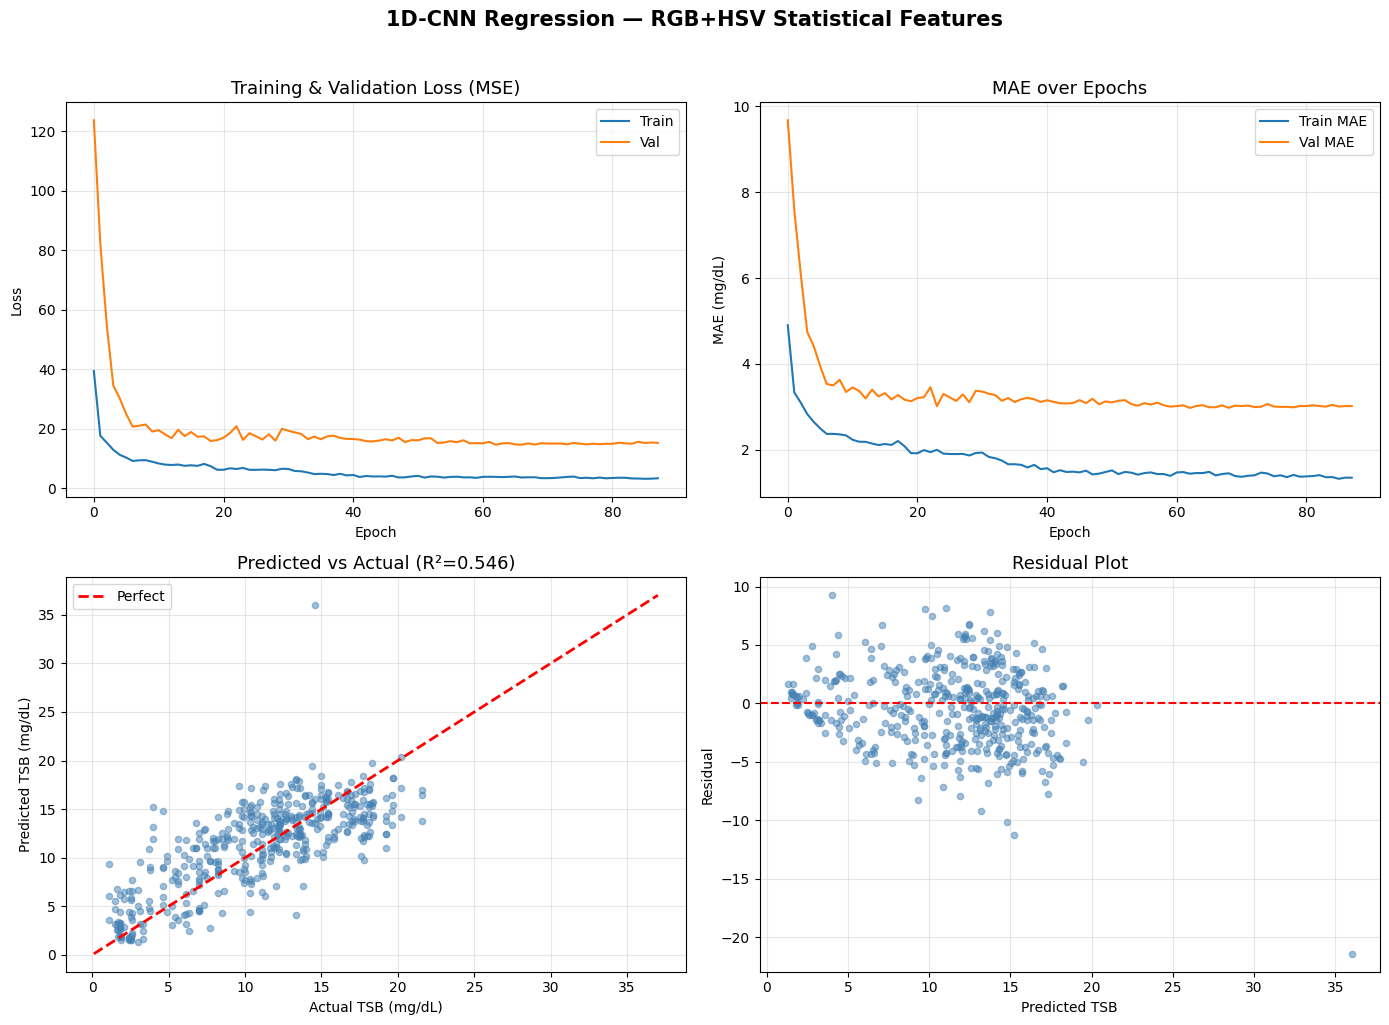

In [10]:
# ════════════════════════════════════════════════════════════════
# Cell 10: Regression visualizations
# ════════════════════════════════════════════════════════════════
h = history_reg.history

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loss curves
axes[0,0].plot(h['loss'], label='Train', lw=1.5)
axes[0,0].plot(h['val_loss'], label='Val', lw=1.5)
axes[0,0].set_title('Training & Validation Loss (MSE)', fontsize=13)
axes[0,0].set_xlabel('Epoch'); axes[0,0].set_ylabel('Loss')
axes[0,0].legend(); axes[0,0].grid(True, alpha=0.3)

# MAE curves
axes[0,1].plot(h['mae'], label='Train MAE', lw=1.5)
axes[0,1].plot(h['val_mae'], label='Val MAE', lw=1.5)
axes[0,1].set_title('MAE over Epochs', fontsize=13)
axes[0,1].set_xlabel('Epoch'); axes[0,1].set_ylabel('MAE (mg/dL)')
axes[0,1].legend(); axes[0,1].grid(True, alpha=0.3)

# Predicted vs Actual
axes[1,0].scatter(y_reg_test, y_pred_reg, alpha=0.5, s=20, c='steelblue')
lims = [min(y_reg_test.min(), y_pred_reg.min())-1, max(y_reg_test.max(), y_pred_reg.max())+1]
axes[1,0].plot(lims, lims, 'r--', lw=2, label='Perfect')
axes[1,0].set_xlabel('Actual TSB (mg/dL)'); axes[1,0].set_ylabel('Predicted TSB (mg/dL)')
axes[1,0].set_title(f'Predicted vs Actual (R²={r2_:.3f})', fontsize=13)
axes[1,0].legend(); axes[1,0].grid(True, alpha=0.3)

# Residuals
residuals = y_reg_test - y_pred_reg
axes[1,1].scatter(y_pred_reg, residuals, alpha=0.5, s=20, c='steelblue')
axes[1,1].axhline(0, color='r', ls='--', lw=1.5)
axes[1,1].set_xlabel('Predicted TSB'); axes[1,1].set_ylabel('Residual')
axes[1,1].set_title('Residual Plot', fontsize=13)
axes[1,1].grid(True, alpha=0.3)

plt.suptitle('1D-CNN Regression — RGB+HSV Statistical Features', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 8 · Build & Train Classification Model

Same 1D-CNN backbone, but output changes to **3-class softmax**.
- Class 0: 0–5 mg/dL (normal)
- Class 1: 5–10 mg/dL (mild)
- Class 2: >10 mg/dL (requires treatment)

In [11]:
# ════════════════════════════════════════════════════════════════
# Cell 11: Build & train classification model
# ════════════════════════════════════════════════════════════════

def build_1dcnn_classification(input_shape, n_classes=3):
    """Same backbone, softmax output."""
    inp = Input(shape=input_shape, name='input')
    
    x = layers.Conv1D(32, 3, padding='same', activation='relu', name='conv1')(inp)
    x = layers.BatchNormalization(name='bn1')(x)
    x = layers.MaxPooling1D(2, padding='same', name='pool1')(x)
    
    x = layers.Conv1D(64, 3, padding='same', activation='relu', name='conv2')(x)
    x = layers.BatchNormalization(name='bn2')(x)
    x = layers.MaxPooling1D(2, padding='same', name='pool2')(x)
    
    x = layers.Conv1D(128, 3, padding='same', activation='relu', name='conv3')(x)
    x = layers.BatchNormalization(name='bn3')(x)
    x = layers.MaxPooling1D(2, padding='same', name='pool3')(x)
    
    x = layers.Conv1D(128, 3, padding='same', activation='relu', name='conv4')(x)
    x = layers.BatchNormalization(name='bn4')(x)
    x = layers.MaxPooling1D(2, padding='same', name='pool4')(x)
    
    x = layers.Flatten(name='flat')(x)
    x = layers.Dense(256, activation='relu', name='fc1')(x)
    x = layers.Dropout(0.3, name='drop1')(x)
    x = layers.Dense(128, activation='relu', name='fc2')(x)
    x = layers.Dropout(0.5, name='drop2')(x)
    out = layers.Dense(n_classes, activation='softmax', name='cls_output')(x)
    
    return Model(inputs=inp, outputs=out, name='1DCNN_Classification')


cls_model = build_1dcnn_classification(X_train.shape[1:])

# Class weights for imbalanced data
cw = compute_class_weight('balanced', classes=np.array([0,1,2]), y=y_cls_train)
class_weight_dict = {i: w for i, w in enumerate(cw)}
print(f'Class weights: {class_weight_dict}')

cls_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_cls = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=25,
        restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=10,
        min_lr=1e-6, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(SAVE_DIR, 'best_1dcnn_cls.keras'),
        monitor='val_accuracy', save_best_only=True, verbose=0)
]

print(f'\nTraining classification model...')
t0 = time.time()
history_cls = cls_model.fit(
    X_train, y_cls_train,
    validation_data=(X_val, y_cls_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=callbacks_cls, verbose=1
)
cls_time = time.time() - t0
cls_epochs = len(history_cls.history['loss'])

print(f'\nDone — {cls_epochs} epochs in {cls_time:.0f}s')
print(f'Best val_accuracy: {max(history_cls.history["val_accuracy"]):.4f}')

Class weights: {0: np.float64(2.1178861788617884), 1: np.float64(1.4234972677595628), 2: np.float64(0.5478443743427971)}

Training classification model...
Epoch 1/200
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4997 - loss: 1.0912 - val_accuracy: 0.4414 - val_loss: 1.0226 - learning_rate: 0.0010
Epoch 2/200
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6328 - loss: 0.7876 - val_accuracy: 0.6667 - val_loss: 0.9045 - learning_rate: 0.0010
Epoch 3/200
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7115 - loss: 0.6432 - val_accuracy: 0.4189 - val_loss: 0.9668 - learning_rate: 0.0010
Epoch 4/200
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7569 - loss: 0.5337 - val_accuracy: 0.4189 - val_loss: 0.9152 - learning_rate: 0.0010
Epoch 5/200
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7806 - loss: 0.4977 - val_accuracy: 0.7117 - val_loss: 0.6661 - learning_rate: 0.0010
Epoch 6/200
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8132 - loss: 0.3976 - val

---
## 9 · Classification Evaluation

In [12]:
# ════════════════════════════════════════════════════════════════
# Cell 12: Classification evaluation
# ════════════════════════════════════════════════════════════════
best_cls_path = os.path.join(SAVE_DIR, 'best_1dcnn_cls.keras')
if os.path.exists(best_cls_path):
    cls_model = tf.keras.models.load_model(best_cls_path)
    print('✅ Loaded best classification model')

y_pred_prob = cls_model.predict(X_test, verbose=0)
y_pred_cls  = np.argmax(y_pred_prob, axis=1)

acc  = accuracy_score(y_cls_test, y_pred_cls)
prec, rec, f1, _ = precision_recall_fscore_support(
    y_cls_test, y_pred_cls, average='weighted', zero_division=0)

print('\n' + '='*60)
print('🎯 CLASSIFICATION RESULTS (Test Set) — 1D-CNN + RGB+HSV')
print('='*60)
print(f'  Accuracy  : {acc*100:.2f}%    (paper: 96.87%)')
print(f'  Precision : {prec*100:.2f}%    (paper: 94.75%)')
print(f'  Recall    : {rec*100:.2f}%    (paper: 92.69%)')
print(f'  F1-Score  : {f1*100:.2f}%    (paper: 93.72%)')
print('='*60)

print('\n📋 Per-class breakdown:')
print(classification_report(
    y_cls_test, y_pred_cls,
    target_names=class_names, zero_division=0))

cm = confusion_matrix(y_cls_test, y_pred_cls)
print(f'Confusion Matrix:\n{cm}')

✅ Loaded best classification model

🎯 CLASSIFICATION RESULTS (Test Set) — 1D-CNN + RGB+HSV
  Accuracy  : 74.44%    (paper: 96.87%)
  Precision : 72.79%    (paper: 94.75%)
  Recall    : 74.44%    (paper: 92.69%)
  F1-Score  : 73.25%    (paper: 93.72%)

📋 Per-class breakdown:
              precision    recall  f1-score   support

   0-5 mg/dL       0.76      0.74      0.75        72
  5-10 mg/dL       0.53      0.39      0.45       105
   >10 mg/dL       0.80      0.88      0.84       273

    accuracy                           0.74       450
   macro avg       0.69      0.67      0.68       450
weighted avg       0.73      0.74      0.73       450

Confusion Matrix:
[[ 53  11   8]
 [ 11  41  53]
 [  6  26 241]]


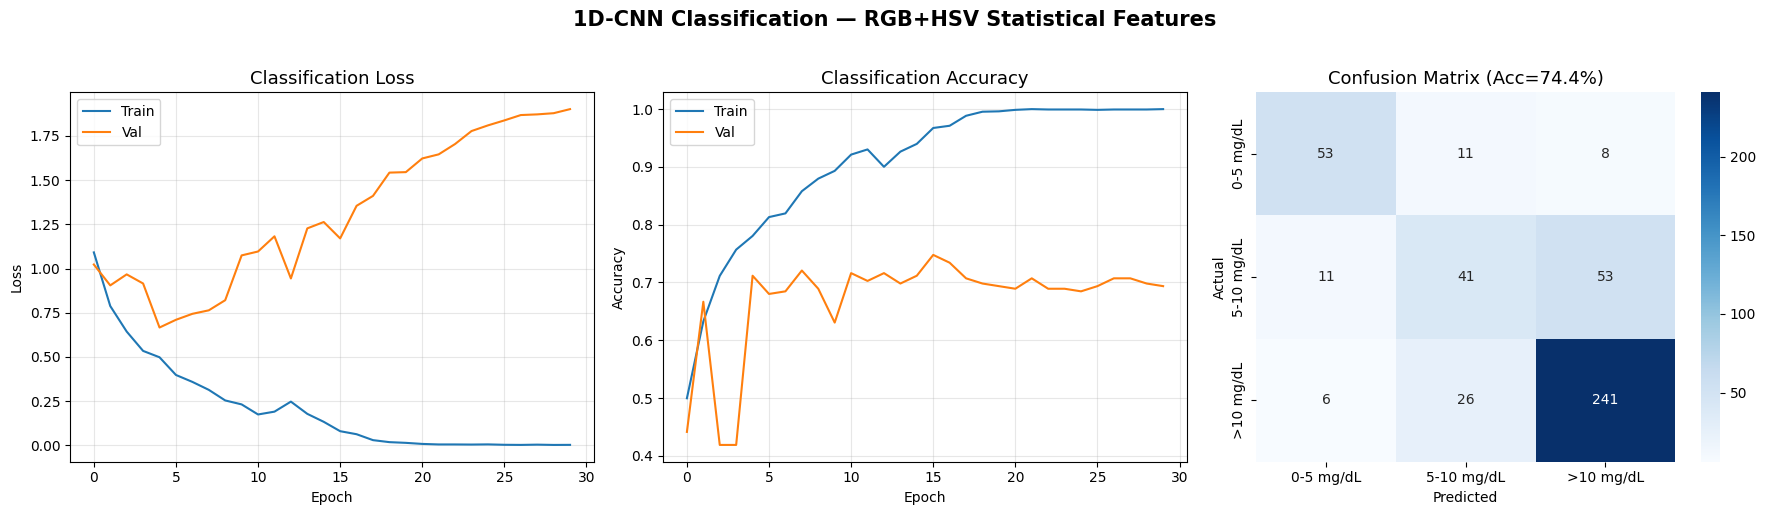

In [13]:
# ════════════════════════════════════════════════════════════════
# Cell 13: Classification visualizations
# ════════════════════════════════════════════════════════════════
hc = history_cls.history

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss
axes[0].plot(hc['loss'], label='Train', lw=1.5)
axes[0].plot(hc['val_loss'], label='Val', lw=1.5)
axes[0].set_title('Classification Loss', fontsize=13)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(hc['accuracy'], label='Train', lw=1.5)
axes[1].plot(hc['val_accuracy'], label='Val', lw=1.5)
axes[1].set_title('Classification Accuracy', fontsize=13)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

# Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[2])
axes[2].set_title(f'Confusion Matrix (Acc={acc*100:.1f}%)', fontsize=13)
axes[2].set_ylabel('Actual'); axes[2].set_xlabel('Predicted')

plt.suptitle('1D-CNN Classification — RGB+HSV Statistical Features',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 10 · Summary & Paper Comparison

In [14]:
# ════════════════════════════════════════════════════════════════
# Cell 14: Summary & save results
# ════════════════════════════════════════════════════════════════

print('\n' + '='*70)
print('    IMPLEMENTATION SUMMARY vs PAPER  (Makhloughi, 2025)')
print('='*70)
print(f'\n  {"Metric":<25} {"Our Result":<15} {"Paper":<15}')
print(f'  {"-"*55}')
print(f'  {"RMSE (mg/dL)":<25} {rmse_:<15.4f} {"1.13":<15}')
print(f'  {"MAE (mg/dL)":<25} {mae_:<15.4f} {"0.89":<15}')
print(f'  {"R²":<25} {r2_:<15.4f} {"0.91":<15}')
print(f'  {"Accuracy (%)":<25} {acc*100:<15.2f} {"96.87":<15}')
print(f'  {"Precision (%)":<25} {prec*100:<15.2f} {"94.75":<15}')
print(f'  {"Recall (%)":<25} {rec*100:<15.2f} {"92.69":<15}')
print(f'  {"F1-Score (%)":<25} {f1*100:<15.2f} {"93.72":<15}')
print('='*70)

print(f'\n  Configuration:')
print(f'    Architecture   : 1D-CNN (4 conv blocks + BN) — Table 2')
print(f'    Color spaces   : RGB + HSV')
print(f'    Features       : 36-dim (6 channels × 6 statistics)')
print(f'    Split          : 70/10/20 (patient-level, stratified)')
print(f'    Optimizer      : Adam (LR={LR}, ReduceLROnPlateau)')
print(f'    Batch size     : {BATCH_SIZE}')
print(f'    Reg epochs     : {reg_epochs} / {EPOCHS}')
print(f'    Cls epochs     : {cls_epochs} / {EPOCHS}')

# Save to JSON
results = {
    'paper': 'Makhloughi (2025) - 10.1038/s41598-025-96100-9',
    'method': '1D-CNN with RGB+HSV statistical color features',
    'regression': {
        'rmse': float(rmse_), 'mae': float(mae_), 'r2': float(r2_),
        'epochs': reg_epochs
    },
    'classification': {
        'accuracy': float(acc), 'precision': float(prec),
        'recall': float(rec), 'f1': float(f1),
        'epochs': cls_epochs,
        'confusion_matrix': cm.tolist()
    },
    'data': {
        'total': len(X_all), 'train': len(X_train),
        'val': len(X_val), 'test': len(X_test),
        'patients_train': len(train_p),
        'patients_val': len(val_p),
        'patients_test': len(test_p)
    }
}

out_path = os.path.join(SAVE_DIR, '1dcnn_neojaundice_results.json')
with open(out_path, 'w') as f:
    json.dump(results, f, indent=2)
print(f'\n✅ Results saved to: {out_path}')


    IMPLEMENTATION SUMMARY vs PAPER  (Makhloughi, 2025)

  Metric                    Our Result      Paper          
  -------------------------------------------------------
  RMSE (mg/dL)              3.4114          1.13           
  MAE (mg/dL)               2.6597          0.89           
  R²                        0.5462          0.91           
  Accuracy (%)              74.44           96.87          
  Precision (%)             72.79           94.75          
  Recall (%)                74.44           92.69          
  F1-Score (%)              73.25           93.72          

  Configuration:
    Architecture   : 1D-CNN (4 conv blocks + BN) — Table 2
    Color spaces   : RGB + HSV
    Features       : 36-dim (6 channels × 6 statistics)
    Split          : 70/10/20 (patient-level, stratified)
    Optimizer      : Adam (LR=0.001, ReduceLROnPlateau)
    Batch size     : 32
    Reg epochs     : 88 / 200
    Cls epochs     : 30 / 200

✅ Results saved to: /Users/shubhbhateja/C